# Data Leakage Detection in Cloud Storage
**Leakage-safe reproduction and improvement of Harahap & Hasibuan (2025)**

Dataset: [Data Leakage Detection](https://www.kaggle.com/datasets/syedmarslanalvi/data-leakage-detection) (Kaggle), 49,500 events, 15 columns.

Run all cells top to bottom (**Runtime > Run all** in Colab). The test set is locked until Step 9 and used once.

## 0. Setup

In [1]:
# Works in Google Colab and locally. In Colab: installs packages and asks for the CSV if it is missing.
import os, sys, json, shutil, warnings
warnings.filterwarnings('ignore')
DATA = 'data/raw/Data_Leakage_Detection.csv'
# Using Google Drive instead? Mount it and point DATA at the file, e.g.
# from google.colab import drive; drive.mount('/content/drive')
# DATA = '/content/drive/MyDrive/leakage_project/Data_Leakage_Detection.csv'

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    !pip install -q imbalanced-learn xgboost
    if not os.path.exists(DATA):
        os.makedirs('data/raw', exist_ok=True)
        from google.colab import files
        for name in files.upload():            # choose Data_Leakage_Detection.csv
            shutil.move(name, DATA)

os.makedirs('results', exist_ok=True); os.makedirs('models', exist_ok=True)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import sklearn, imblearn, xgboost
print('dataset found:', os.path.exists(DATA))
print('python', sys.version.split()[0], '| scikit-learn', sklearn.__version__,
      '| imbalanced-learn', imblearn.__version__, '| xgboost', xgboost.__version__)

dataset found: True
python 3.12.3 | scikit-learn 1.8.0 | imbalanced-learn 0.14.2 | xgboost 3.4.1


## 1. Loading the dataset

In [2]:
df = pd.read_csv(DATA)

# hour of day from 'date' (two text formats; the day/month order of the
# second one is ambiguous, but the hour is not, so only the hour is used)
s = df['date'].astype('string')
dt = pd.to_datetime(s, format='%m/%d/%Y %H:%M', errors='coerce').fillna(
     pd.to_datetime(s, format='%m-%d-%y %H:%M', errors='coerce'))
df['hour'] = dt.dt.hour

label = 'Abnormality'
features9 = ['Authority', 'Through_pwd', 'Through_pin', 'Through_MFA',
             'Data Modification', 'Confidential Data Access',
             'Confidential File Transfer', 'File Operation', 'Data Sensitivity Level']
ED, HOUR = 'External Destination', 'hour'
ALL = features9 + [ED, HOUR]          # id, date, user, pc are never used as features

print(df.shape)
df.head()

(49500, 16)


,id,date,user,pc,Authority,Through_pwd,Through_pin,Through_MFA,Data Modification,Confidential Data Access,Confidential File Transfer,External Destination,File Operation,Data Sensitivity Level,Abnormality,hour
0,1,07-10-14 0:54,User_0971,PC_0258,manager,0.0,0.0,1.0,0.0,0.0,1.0,internal,move,low,0,0.0
1,2,02-01-13 18:08,User_0208,PC_0307,staff,1.0,0.0,0.0,1.0,0.0,0.0,external,write,low,1,18.0
2,3,08-08-11 20:31,User_0265,PC_0259,manager,0.0,0.0,1.0,1.0,0.0,1.0,internal,write,low,0,20.0
3,4,2/26/2020 12:43,User_0178,PC_0154,staff,0.0,1.0,0.0,0.0,1.0,1.0,internal,move,high,0,12.0
4,5,3/13/2012 9:26,User_0556,PC_0095,senior manager,0.0,0.0,1.0,0.0,1.0,0.0,external,read,high,0,9.0


## 2. Data audit

In [3]:
print('Missing values:'); print(df.isna().sum(), '\n')
for col in features9 + [ED]:
    print(f'{col:28s} →', df[col].value_counts(dropna=False).to_dict())
print('\nLabel:'); print(df[label].value_counts())
print(df[label].value_counts(normalize=True).round(3))
print('\nUnparsed dates (hour missing):', df[HOUR].isna().sum())

Missing values:
id                              0
date                          497
user                          496
pc                            498
Authority                     493
Through_pwd                   498
Through_pin                   494
Through_MFA                   353
Data Modification             494
Confidential Data Access      500
Confidential File Transfer    495
External Destination          494
File Operation                494
Data Sensitivity Level        482
Abnormality                     0
hour                          497
dtype: int64 

Authority                    → {'staff': 13880, 'manager': 11898, 'senior manager': 9831, 'intern': 7003, 'lead technician': 6395, nan: 493}
Through_pwd                  → {0.0: 35657, 1.0: 13345, nan: 498}
Through_pin                  → {0.0: 35103, 1.0: 13903, nan: 494}
Through_MFA                  → {0.0: 25153, 1.0: 23994, nan: 353}
Data Modification            → {0.0: 29961, 1.0: 19045, nan: 494}
Confidential Data Ac

**Audit.** 34,105 normal (68.9%) and 15,395 leakage (31.1%) events. About 1% of values are missing in every attribute (353 in `Through_MFA`, none in the label); imputation is done inside the pipeline after the split. A model that always predicts "normal" already reaches **68.9% accuracy**, only 1.9 points below the article's 70.84%.

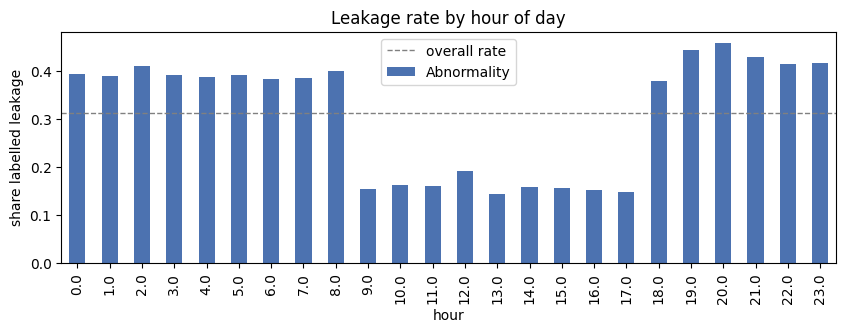

leakage rate 09:00-17:59: 0.158 | outside: 0.404


In [4]:
rate = df.groupby(HOUR)[label].mean()
ax = rate.plot(kind='bar', figsize=(10, 3), color='#4C72B0')
ax.axhline(df[label].mean(), color='grey', ls='--', lw=1, label='overall rate')
ax.set_title('Leakage rate by hour of day'); ax.set_ylabel('share labelled leakage'); ax.legend()
plt.savefig('results/leakage_by_hour.png', dpi=150, bbox_inches='tight'); plt.show()
work = df[HOUR].between(9, 17)
print('leakage rate 09:00-17:59:', round(df.loc[work, label].mean(), 3),
      '| outside:', round(df.loc[~work & df[HOUR].notna(), label].mean(), 3))

**Hour of day.** The leakage rate is **40.4% outside 09:00–17:59 and 15.8% inside it**. The article did not use the `date` column; the hour is observable at the time of the event, so it is a legitimate behavioural attribute.

## 3. Performance ceiling

In [5]:
def ceiling_report(cols, name):
    # missing values are treated as their own category
    key = df[cols].astype(str).fillna('nan').agg('|'.join, axis=1)
    tab = pd.crosstab(key, df[label])
    n = len(df)
    return {'attributes': name, 'combinations': len(tab),
            'majority': round(df[label].value_counts(normalize=True).max(), 4),
            'ceiling Acc*': round(tab.max(axis=1).sum() / n, 4),
            'mixed share c': round(tab[tab.min(axis=1) > 0].sum(axis=1).sum() / n, 4)}

ceil = pd.DataFrame([ceiling_report(features9, 'Nine attributes (article)'),
                     ceiling_report(features9 + [ED], '+ External Destination')])
ceil.to_csv('results/ceiling.csv', index=False)
ceil

,attributes,combinations,majority,ceiling Acc*,mixed share c
0,Nine attributes (article),4689,0.689,0.7434,0.9114
1,+ External Destination,6737,0.689,0.7792,0.8495


**Performance ceiling** (missing values counted as their own category):

| Attributes | Combinations | Majority | Ceiling Acc* | Mixed share c |
|---|---|---|---|---|
| Nine attributes (article) | 4,689 | 0.689 | **0.743** | 0.911 |
| + External Destination | 6,737 | 0.689 | **0.779** | 0.850 |

- With the article's nine attributes the whole room above the majority baseline is **5.4 points**; the article's 70.84% uses about a third of it.
- 91% of events share their attribute combination with events of the other label, so much higher accuracy on these attributes would be suspicious.
- The ceiling is optimistic (rare combinations count as correct). It is not computed with `hour`, because 24 extra values split the data into combinations too small to be meaningful.

## 4. Leakage-safe split and reference tree

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

X, y = df[ALL], df[label]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'ap': 'average_precision', 'f1': 'f1', 'recall': 'recall',
           'precision': 'precision', 'acc': 'accuracy'}
print('Train:', X_tr.shape, ' Test:', X_te.shape, '(test set locked)')

def make_prep(cols):
    # categorical attributes: impute + one-hot; hour: impute, kept numeric
    cat = [c for c in cols if c != HOUR]
    steps = [('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                               ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat)]
    if HOUR in cols:
        steps.append(('num', SimpleImputer(strategy='median'), [HOUR]))
    return ColumnTransformer(steps, verbose_feature_names_out=False)

def tree_pipe(cols, **params):
    return Pipeline([('prep', make_prep(cols)),
                     ('tree', DecisionTreeClassifier(random_state=42, **params))])

def cv_row(name, model, cols):
    s = cross_validate(model, X_tr[cols], y_tr, cv=cv, scoring=scoring, n_jobs=-1)
    return {'model': name, **{m: round(s[f'test_{m}'].mean(), 4) for m in scoring},
            'f1_std': round(s['test_f1'].std(), 4)}

baseline = tree_pipe(features9, criterion='entropy', max_depth=3)
ref_cv = pd.DataFrame([cv_row('Reference tree (entropy, depth 3)', baseline, features9)])
ref_cv

Train: (39600, 11)  Test: (9900, 11) (test set locked)


,model,ap,f1,recall,precision,acc,f1_std
0,"Reference tree (entropy, depth 3)",0.4431,0.2218,0.1509,0.5279,0.6913,0.0826


**Reference tree, leakage-safe.** Under a split-first pipeline the article's tree (entropy, depth 3) is barely above the majority baseline (accuracy 0.691 vs 0.689), misses **85% of leakage events** (recall 0.151) and is unstable across folds (F1 0.222 ± 0.083). PR-AUC 0.443 is above the leakage prevalence (0.311): the tree ranks events reasonably, but the default 0.5 threshold almost never fires.

## 5. Tuning the decision tree with class weights (nine attributes)

In [7]:
param_grid = {'tree__criterion': ['gini', 'entropy'],
              'tree__max_depth': [3, 5, 7, 10, None],
              'tree__min_samples_leaf': [1, 20, 50, 100],
              'tree__class_weight': [None, 'balanced']}
gs9 = GridSearchCV(tree_pipe(features9), param_grid, cv=cv, scoring=scoring, refit='ap', n_jobs=-1)
gs9.fit(X_tr[features9], y_tr)
print('Best:', gs9.best_params_)
res = pd.DataFrame(gs9.cv_results_)
cols = ['param_tree__class_weight', 'param_tree__criterion', 'param_tree__max_depth',
        'param_tree__min_samples_leaf', 'mean_test_ap', 'mean_test_f1', 'mean_test_recall',
        'mean_test_precision', 'mean_test_acc']
res.sort_values('mean_test_ap', ascending=False)[cols].head(8).round(4)

Best: {'tree__class_weight': 'balanced', 'tree__criterion': 'entropy', 'tree__max_depth': 10, 'tree__min_samples_leaf': 20}


,param_tree__class_weight,param_tree__criterion,param_tree__max_depth,param_tree__min_samples_leaf,mean_test_ap,mean_test_f1,mean_test_recall,mean_test_precision,mean_test_acc
73,balanced,entropy,10,20,0.4995,0.5521,0.7114,0.4513,0.6411
33,NaN,entropy,10,20,0.4994,0.4021,0.3214,0.5397,0.7034
53,balanced,gini,10,20,0.4994,0.5519,0.7113,0.4510,0.6408
48,balanced,gini,7,1,0.4991,0.5480,0.6919,0.4545,0.6453
13,NaN,gini,10,20,0.4990,0.4040,0.3238,0.5395,0.7035
68,balanced,entropy,7,1,0.4986,0.5486,0.6910,0.4555,0.6465
28,NaN,entropy,7,1,0.4986,0.4048,0.3228,0.5456,0.7053
8,NaN,gini,7,1,0.4976,0.4035,0.3216,0.5436,0.7046


**Tuning (nine attributes).** The best tree is entropy, depth 10, min_samples_leaf 20, class_weight balanced: PR-AUC 0.500, F1 0.552, recall 0.711.

- PR-AUC is the same with and without class weights (0.4995 vs 0.4994): weighting does not improve ranking, it only moves the decision point. The threshold is therefore the main lever (Step 8).
- The top eight configurations lie within 0.002 PR-AUC, so the exact settings matter little.

## 6. Attributes: External Destination and hour

In [8]:
best9 = {k.replace('tree__', ''): v for k, v in gs9.best_params_.items()}
feature_sets = {'Nine attributes': features9,
                '+ External Destination': features9 + [ED],
                '+ hour': features9 + [HOUR],
                '+ External Destination + hour': ALL}
attr = pd.DataFrame([cv_row(n, tree_pipe(c, **best9), c) for n, c in feature_sets.items()])
attr.to_csv('results/attribute_experiments.csv', index=False)
attr

,model,ap,f1,recall,precision,acc,f1_std
0,Nine attributes,0.4995,0.5521,0.7114,0.4513,0.6411,0.0101
1,+ External Destination,0.5448,0.6304,0.7770,0.5303,0.7166,0.0069
2,+ hour,0.5579,0.5820,0.7096,0.4934,0.6830,0.0016
3,+ External Destination + hour,0.6219,0.6294,0.7313,0.5527,0.7323,0.0063


In [9]:
# target-leakage check: both attributes shift the risk but do not determine the label
print(pd.crosstab(X_tr[ED], y_tr, normalize='index').round(3), '\n')
print(pd.crosstab(X_tr[HOUR].between(9, 17).map({True: '09-17', False: 'other'}), y_tr,
                  normalize='index').round(3))

Abnormality               0      1
External Destination              
external              0.610  0.390
internal              0.741  0.259 

Abnormality      0      1
hour                     
09-17        0.842  0.158
other        0.597  0.403


**Attributes matter more than the algorithm.** Same tree, same folds, only the attribute set changes:

| Attributes | PR-AUC | F1 | Recall | Precision | Accuracy |
|---|---|---|---|---|---|
| Nine attributes | 0.500 | 0.552 | 0.711 | 0.451 | 0.641 |
| + External Destination | 0.545 | **0.630** | **0.777** | 0.530 | 0.717 |
| + hour | 0.558 | 0.582 | 0.710 | 0.493 | 0.683 |
| **+ External Destination + hour** | **0.622** | 0.629 | 0.731 | **0.553** | **0.732** |

- Each attribute alone adds about 0.05 PR-AUC, and together they add **+0.12**. That is roughly ten times the gap between models (Step 7).
- At the default threshold, F1 is the same with or without `hour` (0.630 vs 0.629). The gain from `hour` is in **ranking**: it lets the model put the riskiest events first, which matters when analysts can only review a limited number of alerts (Step 8).
- **Target-leakage check:** external destinations have a 39.0% leakage rate against 25.9% for internal ones, and off-hours 40.3% against 15.8% in working hours. Both attributes shift the risk without determining the label, and both are known when the event happens, so they are genuine behavioural signals, not leakage.

## 7. Comparing models and imbalance strategies (final attributes)

In [10]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
pos_w = (y_tr == 0).sum() / (y_tr == 1).sum()

def make_pipe(model, cols=ALL):
    return Pipeline([('prep', make_prep(cols)), ('model', model)])

searches = {
    'Decision Tree': (DecisionTreeClassifier(class_weight='balanced', random_state=42),
        {'model__criterion': ['gini', 'entropy'], 'model__max_depth': [7, 10, None],
         'model__min_samples_leaf': [1, 20, 50]}),
    'Random Forest': (RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                             random_state=42, n_jobs=1),
        {'model__max_depth': [10, None], 'model__min_samples_leaf': [1, 20]}),
    'XGBoost': (XGBClassifier(n_estimators=300, scale_pos_weight=pos_w, eval_metric='logloss',
                              random_state=42, n_jobs=1),
        {'model__max_depth': [3, 6], 'model__learning_rate': [0.05, 0.1]}),
}
rows, best = [], {}
for name, (model, grid) in searches.items():
    g = GridSearchCV(make_pipe(model), grid, cv=cv, scoring=scoring, refit='ap', n_jobs=-1)
    g.fit(X_tr[ALL], y_tr)
    i, r = g.best_index_, g.cv_results_
    rows.append({'model': name, **{m: round(r[f'mean_test_{m}'][i], 4) for m in scoring},
                 'params': {k.replace('model__', ''): v for k, v in g.best_params_.items()}})
    best[name] = g
models_cmp = pd.DataFrame(rows)
models_cmp.to_csv('results/model_comparison.csv', index=False)
models_cmp

,model,ap,f1,recall,precision,acc,params
0,Decision Tree,0.6219,0.6294,0.7313,0.5527,0.7323,"{'criterion': 'entropy', 'max_depth': 10, 'min..."
1,Random Forest,0.6331,0.6367,0.7641,0.5458,0.7289,"{'max_depth': 10, 'min_samples_leaf': 1}"
2,XGBoost,0.6344,0.6366,0.7256,0.5670,0.7423,"{'learning_rate': 0.05, 'max_depth': 6}"


**Model comparison** (final attributes, same pipeline and folds, each tuned on PR-AUC):

| Model | PR-AUC | F1 | Recall | Precision | Accuracy |
|---|---|---|---|---|---|
| **Decision Tree** (entropy, depth 10, leaf 20) | 0.622 | 0.629 | 0.731 | 0.553 | 0.732 |
| Random Forest (depth 10, leaf 1) | 0.633 | 0.637 | 0.764 | 0.546 | 0.729 |
| XGBoost (depth 6, lr 0.05) | 0.634 | 0.637 | 0.726 | 0.567 | 0.742 |

The ensembles gain only about **0.01 PR-AUC**, against +0.12 from the attributes. The decision tree is kept: nearly the same performance, readable IF-THEN rules, and the model family of the reference article, so the comparison stays fair.

In [11]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTEN, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

tree_params = {k.replace('model__', ''): v for k, v in best['Decision Tree'].best_params_.items()}
tree_params['random_state'] = 42
balancers = {'class_weight = balanced': None, 'SMOTEN': SMOTEN(random_state=42),
             'Random oversampling': RandomOverSampler(random_state=42),
             'Random undersampling': RandomUnderSampler(random_state=42)}
rows = []
for name, sampler in balancers.items():
    steps = [('impute', SimpleImputer(strategy='most_frequent').set_output(transform='pandas'))]
    if sampler is not None:
        steps.append(('sampler', sampler))           # training folds only
    cw = 'balanced' if sampler is None else None
    steps += [('prep', make_prep(ALL)), ('tree', DecisionTreeClassifier(class_weight=cw, **tree_params))]
    s = cross_validate(ImbPipeline(steps), X_tr[ALL], y_tr, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({'balancer': name, **{m: round(s[f'test_{m}'].mean(), 4) for m in scoring}})
bal = pd.DataFrame(rows); bal.to_csv('results/imbalance_strategies.csv', index=False)
print('tree:', tree_params); bal

tree: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 20, 'random_state': 42}


,balancer,ap,f1,recall,precision,acc
0,class_weight = balanced,0.6203,0.6275,0.7226,0.5547,0.7332
1,SMOTEN,0.6011,0.6092,0.6783,0.5534,0.7295
2,Random oversampling,0.6121,0.6251,0.7049,0.5617,0.7371
3,Random undersampling,0.6101,0.6274,0.7235,0.5540,0.7328


**Imbalance strategies** (selected tree; resamplers run inside the pipeline on training folds only):

| Strategy | PR-AUC | F1 | Recall | Precision |
|---|---|---|---|---|
| **class_weight = balanced** | **0.620** | **0.628** | 0.723 | 0.555 |
| SMOTEN | 0.601 | 0.609 | 0.678 | 0.553 |
| Random oversampling | 0.612 | 0.625 | 0.705 | 0.562 |
| Random undersampling | 0.610 | 0.627 | 0.724 | 0.554 |

Class weighting is best or tied on every metric, needs no synthetic data and is the fastest. SMOTEN is the weakest and slowest: synthesising events in data where 85% of combinations are already mixed adds noise, not information. (The class-weight row differs from Step 7 by 0.002 because `hour` is imputed slightly differently in this pipeline.)

## 8. Threshold selection (training data only)

In [12]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
final = best['Decision Tree'].best_estimator_          # refit on all training rows

oof = cross_val_predict(final, X_tr[ALL], y_tr, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, oof)
prec, rec = prec[:-1], rec[:-1]
tab = pd.DataFrame({'threshold': thr, 'precision': prec, 'recall': rec,
                    'f1': 2 * prec * rec / (prec + rec + 1e-12),
                    'alert_rate': [(oof >= t).mean() for t in thr]})

r_star = 0.80
row_f1 = tab.loc[tab.f1.idxmax()]
cand = tab[tab.recall >= r_star]
row_r = cand.loc[cand.precision.idxmax()]
theta = float(row_r.threshold)
print(pd.DataFrame([row_f1, row_r], index=['Maximum F1', f'Most precise with recall ≥ {r_star}']).round(4))
print('\nchosen θ* =', round(theta, 4))

                                threshold  precision  recall      f1  \
Maximum F1                         0.5346     0.5770  0.6984  0.6320   
Most precise with recall ≥ 0.8     0.4162     0.5079  0.8001  0.6214   

                                alert_rate  
Maximum F1                          0.3764  
Most precise with recall ≥ 0.8      0.4899  

chosen θ* = 0.4162


In [13]:
# operating points: alerts per 1,000 events at different recall targets (training OOF)
ops = []
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    c = tab[tab.recall >= target]; rr = c.loc[c.precision.idxmax()]
    ops.append({'recall target': target, 'threshold': round(rr.threshold, 3),
                'precision': round(rr.precision, 3), 'recall': round(rr.recall, 3),
                'alerts per 1,000 events': int(round(rr.alert_rate * 1000)),
                'true leaks per 1,000 alerts': int(round(rr.precision * 1000))})
ops = pd.DataFrame(ops); ops.to_csv('results/operating_points.csv', index=False); ops

,recall target,threshold,precision,recall,"alerts per 1,000 events","true leaks per 1,000 alerts"
0,0.5,0.739,0.681,0.502,229,681
1,0.6,0.639,0.640,0.600,292,640
2,0.7,0.529,0.575,0.701,379,575
3,0.8,0.416,0.508,0.800,490,508
4,0.9,0.279,0.442,0.900,633,442


**Threshold selection** (out-of-fold training scores only; the test set is still locked):

| Rule | θ | Precision | Recall | F1 | Alert rate |
|---|---|---|---|---|---|
| Maximum F1 | 0.535 | 0.577 | 0.698 | 0.632 | 37.6% |
| **Most precise with recall ≥ 0.80** | **0.416** | 0.508 | **0.800** | 0.621 | 49.0% |

θ* = 0.416 is selected: in leakage detection a missed event costs more than an extra alert, and reaching recall 0.80 costs only 0.011 F1.

**Operating points** show the full trade-off for a security team. At recall 0.5 about **2 in 3 alerts are real leaks** (229 alerts per 1,000 events). At recall 0.9 it is fewer than 1 in 2 (633 alerts). The ranking gain from `hour` shows mostly at the low-alert end of this table. If analyst capacity is the binding constraint, the recall-0.6 or recall-0.7 rows are the better choice.

## 9. Final evaluation on the locked test set (used once)

In [14]:
from sklearn.metrics import (average_precision_score, f1_score, recall_score, precision_score,
                             accuracy_score, matthews_corrcoef, roc_auc_score, confusion_matrix)
ref = baseline.fit(X_tr[features9], y_tr)

def report(name, y_true, score, t):
    pred = (score >= t).astype(int)
    return {'model': name, 'PR-AUC': average_precision_score(y_true, score),
            'ROC-AUC': roc_auc_score(y_true, score) if score.std() > 0 else 0.5,
            'F1': f1_score(y_true, pred), 'Recall': recall_score(y_true, pred),
            'Precision': precision_score(y_true, pred, zero_division=0),
            'Accuracy': accuracy_score(y_true, pred), 'MCC': matthews_corrcoef(y_true, pred),
            'Alert rate': pred.mean()}

s_final = final.predict_proba(X_te[ALL])[:, 1]
s_ref = ref.predict_proba(X_te[features9])[:, 1]
test = pd.DataFrame([report('Majority (always normal)', y_te, np.zeros(len(y_te)), 0.5),
                     report('Reference tree (article)', y_te, s_ref, 0.5),
                     report(f'Final tree (θ*={theta:.3f})', y_te, s_final, theta)]).round(4)
test.to_csv('results/test_results.csv', index=False)
cm = confusion_matrix(y_te, (s_final >= theta).astype(int))
print('Final tree confusion matrix [[TN FP] [FN TP]]:\n', cm)
test

Final tree confusion matrix [[TN FP] [FN TP]]:
 [[4339 2482]
 [ 532 2547]]


,model,PR-AUC,ROC-AUC,F1,Recall,Precision,Accuracy,MCC,Alert rate
0,Majority (always normal),0.3110,0.5000,0.0000,0.0000,0.0000,0.6890,0.0000,0.0000
1,Reference tree (article),0.4519,0.6878,0.1706,0.1010,0.5495,0.6946,0.1269,0.0572
2,Final tree (θ*=0.416),0.6094,0.8089,0.6283,0.8272,0.5065,0.6956,0.4290,0.5080


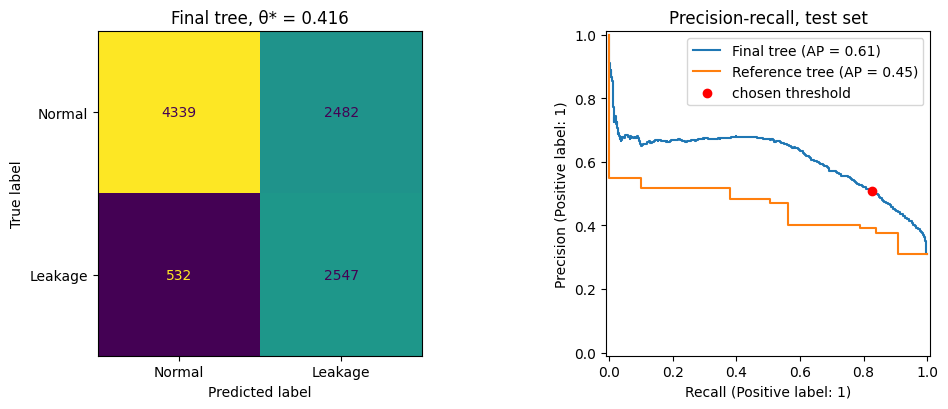

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Leakage']).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f'Final tree, θ* = {theta:.3f}')
PrecisionRecallDisplay.from_predictions(y_te, s_final, ax=axes[1], name='Final tree')
PrecisionRecallDisplay.from_predictions(y_te, s_ref, ax=axes[1], name='Reference tree')
p_ = precision_score(y_te, s_final >= theta); r_ = recall_score(y_te, s_final >= theta)
axes[1].scatter([r_], [p_], color='red', zorder=5, label='chosen threshold'); axes[1].legend()
axes[1].set_title('Precision-recall, test set')
plt.tight_layout(); plt.savefig('results/test_evaluation.png', dpi=150, bbox_inches='tight'); plt.show()

## Final results (test set, 9,900 events, opened once)

| Model | PR-AUC | ROC-AUC | F1 | Recall | Precision | Accuracy | MCC | Alert rate |
|---|---|---|---|---|---|---|---|---|
| Majority (always normal) | 0.311 | 0.500 | 0.000 | 0.000 | 0.000 | 0.689 | 0.000 | 0% |
| Reference tree (article) | 0.452 | 0.688 | 0.171 | 0.101 | 0.550 | 0.695 | 0.127 | 6% |
| **Final tree (θ* = 0.416)** | **0.609** | **0.809** | **0.628** | **0.827** | 0.507 | 0.696 | **0.429** | 51% |

Confusion matrix of the final tree: TN 4,339, FP 2,482, FN 532, TP 2,547.

- **The test results confirm cross-validation** (recall 0.827 vs 0.800, F1 0.628 vs 0.621), so the leakage-safe procedure gave an honest estimate.
- The final tree catches **2,547 of 3,079 leakage events**; the reference tree catches about 311, roughly **eight times fewer**. MCC rises from 0.127 to 0.429 and PR-AUC from 0.452 to 0.609.
- Both trees have almost the same accuracy (about 0.70), yet their recall differs by a factor of eight. Accuracy alone hides the difference that matters.
- **Cost:** about half of all events raise an alert, and about one alert in two is a real leak (precision 0.507). This is the price of the recall ≥ 0.80 target on noisy attributes; the operating-points table shows cheaper settings.

## 10. Explainability: IF-THEN rules and attribute importance

In [16]:
from sklearn.inspection import permutation_importance
prep, tree = final.named_steps['prep'], final.named_steps['model']
names = prep.get_feature_names_out()
enc = prep.named_transformers_['cat'].named_steps['onehot']
cat_cols = prep.transformers_[0][2]
cats = {col: [str(v) for v in vals] for col, vals in zip(cat_cols, enc.categories_)}
t = tree.tree_

def split(i):
    nm = names[t.feature[i]]
    if nm == HOUR:
        return HOUR, None
    col = max((c for c in cats if nm.startswith(c + '_')), key=len)
    return col, nm[len(col) + 1:]

paths = {}
def walk(node, conds):
    if t.children_left[node] == -1:
        paths[node] = conds; return
    col, val = split(node)
    if col == HOUR:
        walk(t.children_left[node], conds + [(HOUR, '≤', t.threshold[node])])
        walk(t.children_right[node], conds + [(HOUR, '>', t.threshold[node])])
    else:
        walk(t.children_left[node], conds + [(col, '≠', val)])
        walk(t.children_right[node], conds + [(col, '=', val)])
walk(0, [])

def pretty(v):
    return {'1.0': '1', '0.0': '0'}.get(v, v)

def readable(conds):
    eq, excl, order, lo, hi = {}, {}, [], None, None
    for c, op, v in conds:
        if c == HOUR:
            if op == '≤': hi = v if hi is None else min(hi, v)
            else: lo = v if lo is None else max(lo, v)
            continue
        if c not in order: order.append(c)
        if op == '=': eq[c] = v
        else: excl.setdefault(c, set()).add(v)
    parts = []
    for c in order:
        if c in eq:
            parts.append(f'{c} = {pretty(eq[c])}')
        else:
            left = [pretty(o) for o in cats[c] if o not in excl[c] and o != 'nan']
            parts.append(f'{c} = {left[0]}' if len(left) == 1 else f"{c} in {{{', '.join(left)}}}")
    if lo is not None or hi is not None:
        a = 0 if lo is None else int(np.floor(lo)) + 1
        b = 23 if hi is None else int(np.floor(hi))
        parts.append(f'hour {a:02d}:00-{b:02d}:59')
    return ' AND '.join(parts)

s_tr = final.predict_proba(X_tr[ALL])[:, 1]
leaf = tree.apply(prep.transform(X_tr[ALL]))
st = (pd.DataFrame({'leaf': leaf, 'y': y_tr.values, 's': s_tr}).groupby('leaf')
        .agg(n=('y', 'size'), leak_rate=('y', 'mean'), score=('s', 'first')))
st['caught'] = (st.n * st.leak_rate).round().astype(int)
alerts = st[st.score >= theta].sort_values('caught', ascending=False)
print(f'Leaves: {len(st)} | leaves raising an alert at θ*: {len(alerts)}\n')
rules = []
for k, (lf, row) in enumerate(alerts.head(5).iterrows(), 1):
    rule = readable(paths[lf]); rules.append({'rule': k, 'IF': rule, 'events': int(row.n),
                                             'leakage rate': round(row.leak_rate, 2), 'caught': int(row.caught)})
    print(f'Rule {k}: IF {rule} THEN leakage')
    print(f'   events={int(row.n)}, leakage rate={row.leak_rate:.2f}, caught={int(row.caught)}\n')
pd.DataFrame(rules).to_csv('results/top_rules.csv', index=False)
print('Top 5 rules cover', round(alerts.head(5).caught.sum() / y_tr.sum(), 3), 'of training leakage events')

Leaves: 545 | leaves raising an alert at θ*: 363

Rule 1: IF Confidential File Transfer = 1 AND External Destination = external AND Authority in {intern, senior manager, staff} AND Through_pwd = 0 AND Data Sensitivity Level in {high, medium} AND hour 00:00-02:59 THEN leakage
   events=369, leakage rate=0.61, caught=225

Rule 2: IF Confidential File Transfer = 1 AND External Destination = external AND Authority in {lead technician, manager, senior manager, staff} AND File Operation in {delete, read} AND Confidential Data Access = 0 AND hour 09:00-14:59 THEN leakage
   events=601, leakage rate=0.35, caught=209

Rule 3: IF Confidential File Transfer = 1 AND External Destination = external AND Authority in {intern, manager, senior manager, staff} AND Through_pwd = 0 AND Data Sensitivity Level in {high, medium} AND File Operation in {delete, move, read} AND hour 03:00-04:59 THEN leakage
   events=249, leakage rate=0.72, caught=180

Rule 4: IF Confidential File Transfer = 1 AND External Dest

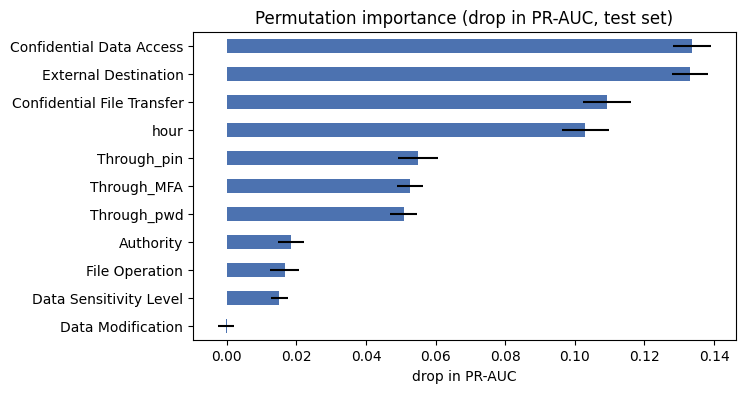

,mean,std
Confidential Data Access,0.1336,0.0055
External Destination,0.1330,0.0052
Confidential File Transfer,0.1091,0.0069
hour,0.1030,0.0067
Through_pin,0.0550,0.0057
Through_MFA,0.0525,0.0037
Through_pwd,0.0508,0.0040
Authority,0.0184,0.0037
File Operation,0.0167,0.0042
Data Sensitivity Level,0.0150,0.0024


In [17]:
pi = permutation_importance(final, X_te[ALL], y_te, scoring='average_precision',
                            n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std},
                   index=ALL).sort_values('mean', ascending=False)
imp.to_csv('results/permutation_importance.csv')
imp['mean'].iloc[::-1].plot(kind='barh', xerr=imp['std'].iloc[::-1], figsize=(7, 4), color='#4C72B0')
plt.title('Permutation importance (drop in PR-AUC, test set)'); plt.xlabel('drop in PR-AUC')
plt.savefig('results/permutation_importance.png', dpi=150, bbox_inches='tight'); plt.show()
imp.round(4)

**Explainability.**

*Permutation importance* (drop in test PR-AUC when one attribute is shuffled):

| Attribute | Importance |
|---|---|
| Confidential Data Access | 0.134 |
| External Destination | 0.133 |
| Confidential File Transfer | 0.109 |
| hour | 0.103 |
| Through_pin / Through_MFA / Through_pwd | 0.055 / 0.053 / 0.051 |
| Authority / File Operation / Data Sensitivity Level | 0.018 / 0.017 / 0.015 |
| Data Modification | 0.000 |

- The two attributes the article did not use, `External Destination` and `hour`, rank **2nd and 4th**. `Data Modification` contributes nothing and could be dropped.

*IF-THEN rules.* The tree has 545 leaves, and 363 of them raise an alert at θ*. **All five rules that catch the most leakage start with "confidential file transfer to an external destination"**, which agrees with the article's main rule. They are then refined by role, authentication and time of day: rules 1, 3 and 4 fire at night (00:00–07:59) with leakage rates of 0.61–0.72.

- **Reading the rates:** with balanced class weights, a leaf raises an alert at θ* = 0.416 when its training leakage rate is at least about **24%**, below the 31% base rate. This is why leaves with rates of 0.35–0.40 (rules 2 and 5) still alert, and why about half of all events are flagged.
- **Limitation:** each alert can be explained by its path, but the rules are long (up to nine conditions), and the five strongest cover only 7% of training leakage events. Detection performance was bought at the cost of the global simplicity of the depth-3 reference tree.

## 11. Saving the model and run record

In [18]:
import joblib
joblib.dump({'model': final, 'threshold': theta, 'features': ALL}, 'models/final_tree.joblib')
run = {'python': sys.version.split()[0], 'sklearn': sklearn.__version__, 'imblearn': imblearn.__version__,
       'xgboost': xgboost.__version__, 'random_state': 42, 'test_size': 0.2, 'features': ALL,
       'tree_params': {k: (v if v is not None else 'None') for k, v in tree_params.items()},
       'threshold': theta, 'recall_target': r_star}
json.dump(run, open('results/run_info.json', 'w'), indent=2)
if IN_COLAB:   # download everything as one zip
    !zip -qr dlp_results.zip results models
    from google.colab import files; files.download('dlp_results.zip')
run

{'python': '3.12.3',
 'sklearn': '1.8.0',
 'imblearn': '0.14.2',
 'xgboost': '3.4.1',
 'random_state': 42,
 'test_size': 0.2,
 'features': ['Authority',
  'Through_pwd',
  'Through_pin',
  'Through_MFA',
  'Data Modification',
  'Confidential Data Access',
  'Confidential File Transfer',
  'File Operation',
  'Data Sensitivity Level',
  'External Destination',
  'hour'],
 'tree_params': {'criterion': 'entropy',
  'max_depth': 10,
  'min_samples_leaf': 20,
  'random_state': 42},
 'threshold': 0.4162147474030673,
 'recall_target': 0.8}

## Conclusion

1. **Reproduction:** evaluated without leakage, the article's depth-3 tree barely beats a model that always predicts "normal" (accuracy 0.695 vs 0.689) and catches only 10% of leakage events on the test set.
2. **Improvement:** a tuned, class-weighted tree with two extra attributes (`External Destination`, `hour`) and a threshold chosen for recall ≥ 0.80 catches **83% of leakage events** (8× more), with PR-AUC 0.609 and MCC 0.429.
3. **What mattered:** attributes (+0.12 PR-AUC) far outweigh model choice (+0.01 for ensembles) and imbalance technique (class weights ≥ SMOTEN and resampling).
4. **Limits:** the attributes are coarse and noisy (85% mixed combinations), so precision stays around 0.5 at high recall and about half of events raise an alert. A deployment would need richer behavioural attributes, such as per-user history, to cut analyst workload.

Saved files: `results/` (tables and figures) and `models/final_tree.joblib` (pipeline + threshold).